In [ ]:
#Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

**Step 1: Exploratory Data Analysis (EDA) & Data Auditing**

● Task 1.1: Load the dataset into a Pandas DataFrame and inspect its
shape, columns, and data types.

In [ ]:
# Loading the data set
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving AB_NYC_2019.csv to AB_NYC_2019.csv


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [ ]:
# 1. Inspect the shape
print("Dataset Shape (rows, columns):")
print(df.shape)

Dataset Shape (rows, columns):
(48895, 16)


In [ ]:
# 2. Inspect the column names
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


In [ ]:
# 3. Inspect the data types
print("\nData Types:")
print(df.dtypes)


Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


● Task 1.2: Identify which columns are numerical (discrete/continuous)
and which are categorical (nominal/ordinal).

In [ ]:
# Numerical columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical Columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


● Task 1.3: Check for missing values across all columns. Write down
which columns have missing data and calculate their percentages.

In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage (%)': missing_percentage
})

# Display only columns that contain missing values
missing_summary = missing_summary[missing_summary['Missing Values'] > 0]



print("Columns with Missing Values:")
print(missing_summary.round(2))


Columns with Missing Values:
                   Missing Values  Missing Percentage (%)
name                           16                    0.03
host_name                      21                    0.04
last_review                 10052                   20.56
reviews_per_month           10052                   20.56


**Step 2: Data Cleaning & Handling Missing Values**

● Task 2.1: Look at the last_review column. Since it's a date string with
over 10,000 missing values, decide whether to drop the column entirely
or engineer it.

In [ ]:
# Check missing values before dropping
print("Missing values in last_review:", df['last_review'].isnull().sum())

# Drop the column
df.drop('last_review', axis=1, inplace=True)

# Verify that the column has been removed
print("\nColumn dropped successfully.")
print("Is last_review present?", 'last_review' in df.columns)


Missing values in last_review: 10052

Column dropped successfully.
Is last_review present? False


● Task 2.2: Look at the reviews_per_month column. If it contains missing
values, investigate why they are missing (Hint: look at the number of
reviews for those rows) and fill them with a logical replacement value.

In [ ]:
# Check why reviews_per_month is missing
print(df[df['reviews_per_month'].isnull()]['number_of_reviews'].value_counts())

# Replace missing numerical values with median
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

# Replace missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

number_of_reviews
0    10052
Name: count, dtype: int64


● Task 2.3: Drop irrelevant identifier columns that won't help a
mathematical model (e.g., URLs, host names, or unique IDs).

In [ ]:
# Drop irrelevant identifier columns
df.drop(['id', 'host_id', 'host_name', 'name'], axis=1, inplace=True)

**Step 3: Outlier Identification & Treatment**

● Task 3.1: Create boxplots or histograms for price and minimum_nights to
visually detect outliers.

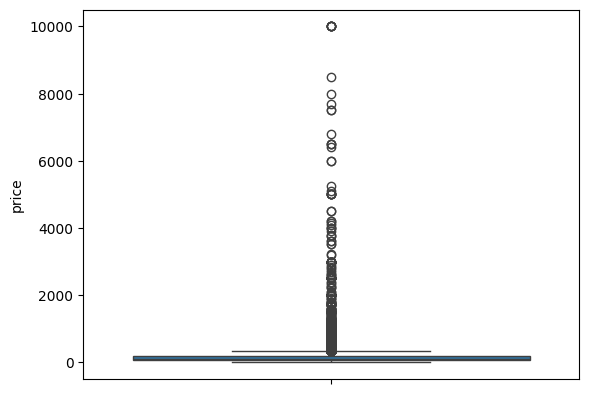

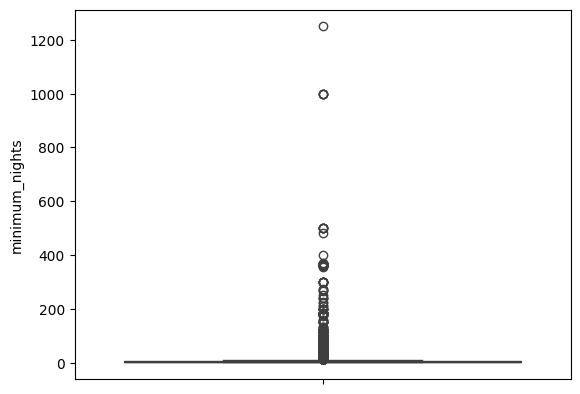

In [ ]:
# Boxplot for outlier detection
sns.boxplot(y=df['price'])
plt.show()

sns.boxplot(y=df['minimum_nights'])
plt.show()

● Task 3.2: Apply a capping or trimming strategy. Use the 95th percentile
rule to remove extreme luxury penthouses (e.g., $10,000/night listings)
and long-term rental rules (e.g., minimum stays of 365+ nights) so the
model focuses on the typical consumer market.

In [ ]:
# Remove outliers using the 95th percentile
price_limit = df['price'].quantile(0.95)
nights_limit = df['minimum_nights'].quantile(0.95)

df = df[(df['price'] <= price_limit) & (df['minimum_nights'] <= nights_limit)]

**Step 4: Feature Selection & Categorical Encoding**

● Task 4.1: Address High Cardinality. The dataset has a neighbourhood
column with 200+ unique values and a neighbourhood_group column
with 5 values. Explain why keeping the 200+ unique values will break the
model's simplicity (The Curse of Dimensionality), and drop the
hyper-specific one.

Explanation: The neighbourhood column contains 200+ unique categories. Keeping them can create many dummy variables during One-Hot Encoding, increasing model complexity and dimensionality. This is known as the Curse of Dimensionality. Therefore, we drop neighbourhood and retain neighbourhood_group, which has only 5 categories

In [ ]:
# Drop high-cardinality column
# Drop neighbourhood if it exists
df.drop('neighbourhood', axis=1, inplace=True, errors='ignore')
print(df.columns.tolist())

['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


● Task 4.2: Convert the remaining categorical columns
(neighbourhood_group and room_type) into numerical format using
One-Hot Encoding. Ensure they drop the first column to avoid the
"Dummy Variable Trap."

In [ ]:
# One-Hot Encoding
cols = [col for col in ['neighbourhood_group', 'room_type'] if col in df.columns]
df = pd.get_dummies(df, columns=cols, drop_first=True, dtype=int)

print(df.head())
print(df.columns.tolist())


   latitude  longitude  price  minimum_nights  number_of_reviews  \
0  40.64749  -73.97237    149               1                  9   
1  40.75362  -73.98377    225               1                 45   
2  40.80902  -73.94190    150               3                  0   
3  40.68514  -73.95976     89               1                270   
4  40.79851  -73.94399     80              10                  9   

   reviews_per_month  calculated_host_listings_count  availability_365  \
0               0.21                               6               365   
1               0.38                               2               355   
2               0.00                               1               365   
3               4.64                               1               194   
4               0.10                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                             1                              0   
1             

**Step 5: Feature-Target Separation & Validation Split**

● Task 5.1: Separate the cleaned data into features ($X$) and the target
variable ($y$).

In [ ]:
# Separate features (X) and target (y)
X = df.drop('price', axis=1)
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45759, 13)
Target shape: (45759,)


● Task 5.2: Split the data into a Training Set (80%) and a Testing Set
(20%). Ensure they use a specific reproducibility seed (random_state) so
their results can be verified.

In [ ]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (36607, 13)
X_test shape: (9152, 13)
y_train shape: (36607,)
y_test shape: (9152,)


**Step 6: Model Training & Evaluation**

● Task 6.1: Import, initialize, and fit a standard Linear Regression model
using the training data.

In [ ]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Initialize the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

LinearRegression()

● Task 6.2: Use the trained model to generate price predictions on the
hidden testing data.

In [ ]:
# Predict prices on the test data
y_pred = model.predict(X_test)

print(y_pred)

[173.31999192 157.35088508 173.11463763 ... 113.56673579 164.83065362
  97.80011253]


● Task 6.3: Calculate three key metrics to grade the model:

○ R-Squared ($R^2$) Score: To find out what percentage of the
price variance the model actually understands.

○ Mean Absolute Error (MAE): To find the average mistake the
model makes in actual US dollars.

○ Mean Squared Error (MSE) / RMSE: To analyze how heavily
the model is being punished for large mistakes.

In [ ]:
# Task 6.3: Model Evaluation
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.47082773500021025
MAE: 38.5408749155387
MSE: 2834.959378892661
RMSE: 53.244336589844565


**Step 7: Residual Analysis & Interpretation**

● Task 7.1: Plot a scatter plot of Actual Prices vs. Predicted Prices. Draw a
$45^\circ$ diagonal line to show what a "perfect" prediction would look
like.

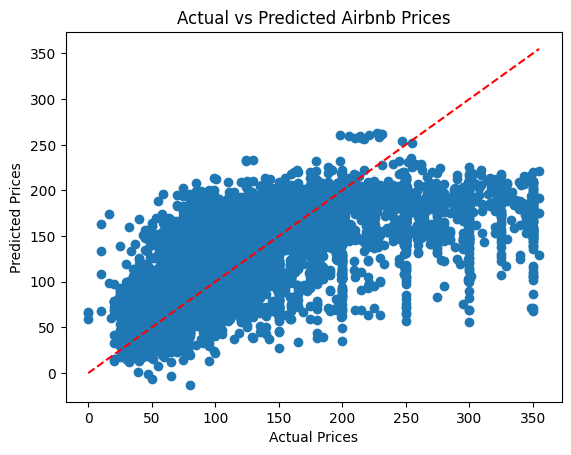

In [ ]:

plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

● Task 7.2: Plot a Residual Plot (Errors vs. Predicted values) or an error
distribution histogram.

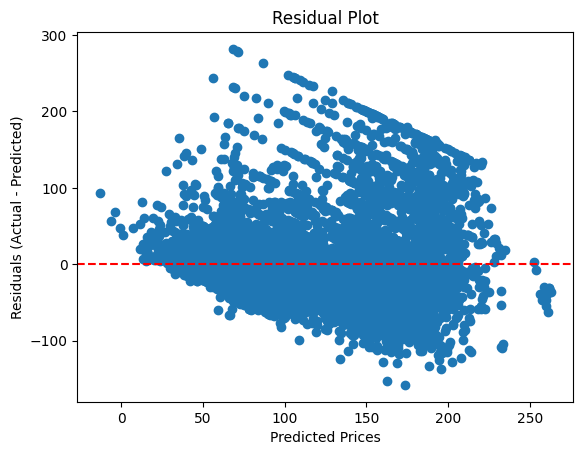

In [ ]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

● Task 7.3: Answer the final project question: Does the model perform
better on cheap listings or expensive listings, and why?

The model generally performs better on cheap Airbnb listings than on expensive listings. Cheap listings tend to have lower prices and smaller prediction errors, while expensive listings often have larger errors because their prices vary more and may be affected by unique features or luxury amenities.

Linear Regression also tries to fit a straight-line relationship, so it may struggle to predict unusually expensive listings accurately.